# Sequential Time-Warping Hidden Markov Model

### Sidney Rafilson, Gyorgy Buzsaki, Alex Williams

Contact: ser9475@nyu.edu

----------------------------------------------------

This notebook contains code for simulating the generative Sequential Time-Warping Hidden Markov Model (STWHMM) with poisson emissions

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from tqdm import tqdm

sns.set_context("talk")

%matplotlib widget


# Defining Model Hyper-Parameters

In [2]:
# number of neurons
N = 100

# number of hidden states
M = 21

# number of time-warp states
S = 11

# define the number of sequences and sequence length
# nSequences * seqLength forward states
# + same number of reverse clones
nSequences = 2
seqLength = 5

assert nSequences * seqLength * 2 == M - 1, \
    "The condition nSequences * seqLength * 2 = M - 1 must be satisfied."

## Transition Matrix

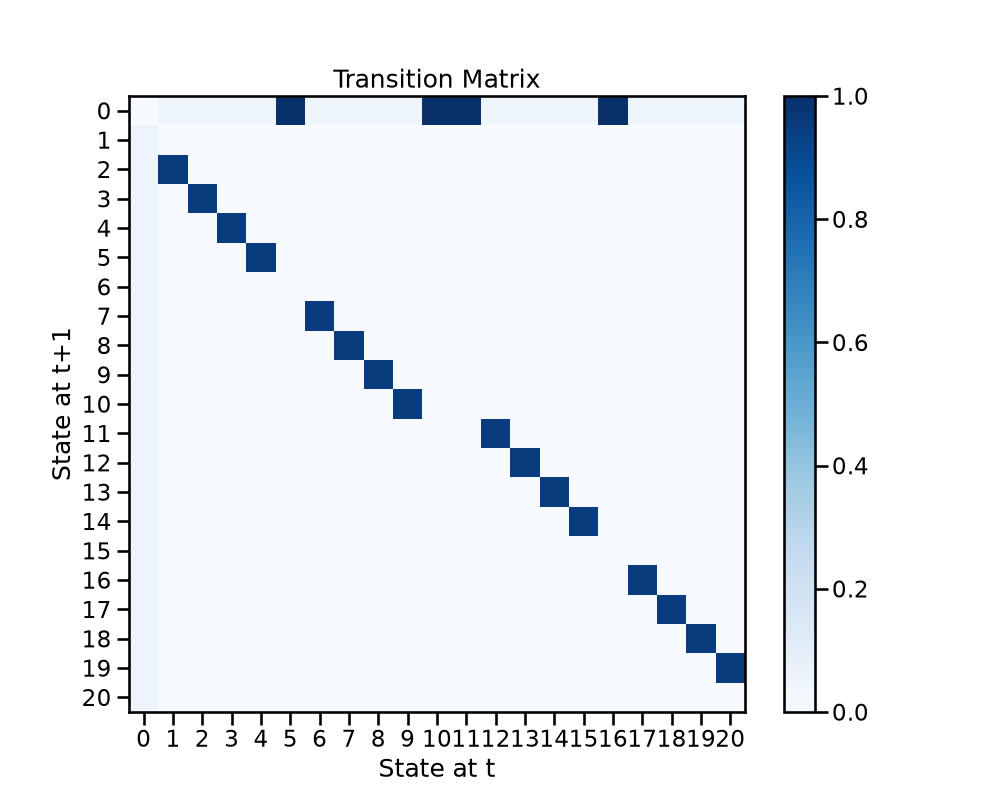

In [49]:
T_star = np.zeros((M, M))

# number of forward states
nForward = (M - 1) // 2


# -----------------------------------------------------------------------------
# Hub transitions
# -----------------------------------------------------------------------------

# From every sequence state -> hub
T_star[0, 1:] = 1 / (M - 1)

# From hub -> every sequence state
T_star[1:, 0] = 1 / (M - 1)


# -----------------------------------------------------------------------------
# Forward and reverse sequence transitions
# -----------------------------------------------------------------------------

for seq in range(nSequences):

    # -----------------------
    # Forward sequence
    # -----------------------

    start_forward = 1 + seq * seqLength
    end_forward = start_forward + seqLength - 1

    for state in range(start_forward, end_forward):
        T_star[state + 1, state] = 1


    # -----------------------
    # Reverse clone sequence
    # -----------------------

    start_reverse = start_forward + nForward
    end_reverse = end_forward + nForward

    # Run through the cloned states in reverse order
    #
    # e.g. 15 -> 14 -> 13 -> 12 -> 11
    for state in range(end_reverse, start_reverse, -1):
        T_star[state - 1, state] = 1


# -----------------------------------------------------------------------------
# Normalize columns so T is column stochastic
# -----------------------------------------------------------------------------

T_star = T_star / T_star.sum(axis=0, keepdims=True)


# visualize transition matrix
plt.figure(figsize=(10, 8))

plt.title("Transition Matrix")

plt.imshow(T_star, cmap="Blues")
plt.colorbar()

plt.xticks(np.arange(M))
plt.yticks(np.arange(M))

plt.xlabel("State at t")
plt.ylabel("State at t+1")

plt.show()

## Emissions Matrix

Assembly size: 10
Number of assemblies: 10

Assembly: 0
Neuron IDs: [0 1 2 3 4 5 6 7 8 9]
Current state: 1
Current sequence: 0
Forward boundaries: 1 5

Assembly: 1
Neuron IDs: [10 11 12 13 14 15 16 17 18 19]
Current state: 2
Current sequence: 0
Forward boundaries: 1 5

Assembly: 2
Neuron IDs: [20 21 22 23 24 25 26 27 28 29]
Current state: 3
Current sequence: 0
Forward boundaries: 1 5

Assembly: 3
Neuron IDs: [30 31 32 33 34 35 36 37 38 39]
Current state: 4
Current sequence: 0
Forward boundaries: 1 5

Assembly: 4
Neuron IDs: [40 41 42 43 44 45 46 47 48 49]
Current state: 5
Current sequence: 0
Forward boundaries: 1 5

Assembly: 5
Neuron IDs: [50 51 52 53 54 55 56 57 58 59]
Current state: 6
Current sequence: 1
Forward boundaries: 6 10

Assembly: 6
Neuron IDs: [60 61 62 63 64 65 66 67 68 69]
Current state: 7
Current sequence: 1
Forward boundaries: 6 10

Assembly: 7
Neuron IDs: [70 71 72 73 74 75 76 77 78 79]
Current state: 8
Current sequence: 1
Forward boundaries: 6 10

Assembly: 8
Neuron 

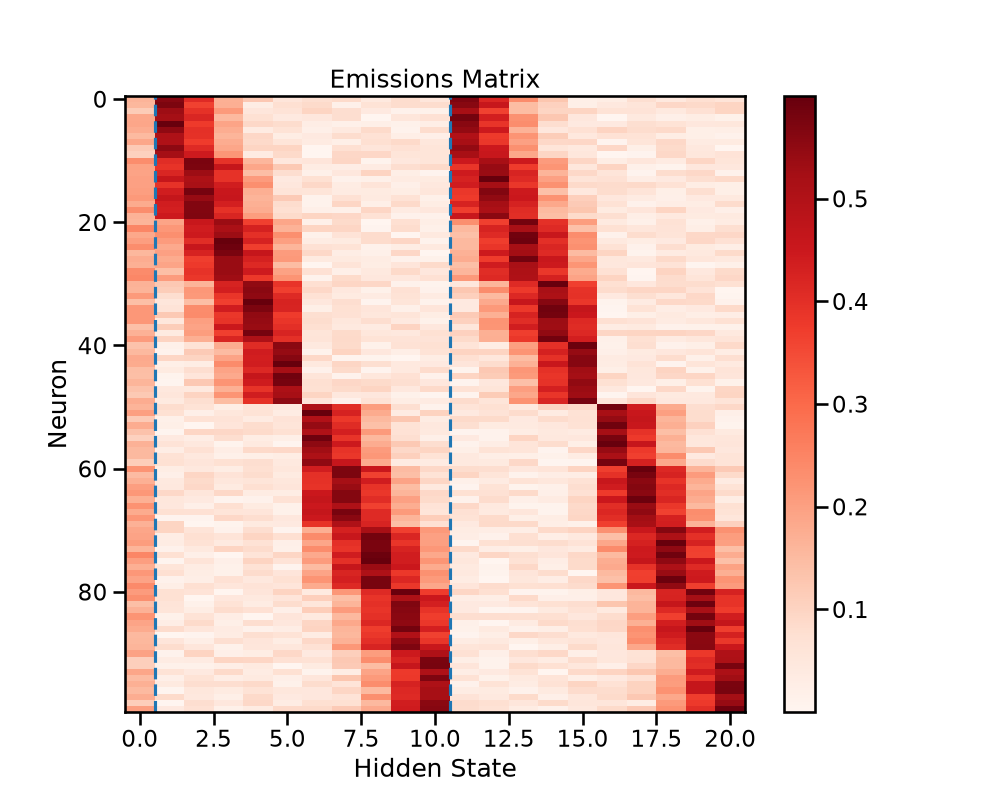

In [50]:
# preallocate emissions matrix
Lambda = np.zeros((N, M))

# scaling factor for Gaussian tuning
scale = 0.5

# standard deviation for gaussian tuning
sigma = 0.5


# -----------------------------------------------------------------------------
# Define neural assemblies
# -----------------------------------------------------------------------------

assemblySize = np.ceil(N / (M - 1) * 2).astype(int)

nAssemblies = N // assemblySize

print("Assembly size:", assemblySize)
print("Number of assemblies:", nAssemblies)


# Number of forward states
nForward = M // 2


# -----------------------------------------------------------------------------
# Give each assembly Gaussian tuning
# -----------------------------------------------------------------------------

# Start at state 1 because state 0 is the hub
current_state = 1


for assembly in range(nAssemblies):

    # neurons belonging to this assembly
    neuronIDs = np.arange(
        assembly * assemblySize,
        min((assembly + 1) * assemblySize, N)
    )

    print("\nAssembly:", assembly)
    print("Neuron IDs:", neuronIDs)


    # -------------------------------------------------------------------------
    # Determine which forward sequence contains the tuning center
    # -------------------------------------------------------------------------

    currentSequence = (current_state - 1) // seqLength

    print("Current state:", current_state)
    print("Current sequence:", currentSequence)


    # forward sequence boundaries
    start_forward = 1 + currentSequence * seqLength
    end_forward = start_forward + seqLength - 1

    print("Forward boundaries:", start_forward, end_forward)


    # -------------------------------------------------------------------------
    # Gaussian tuning
    # -------------------------------------------------------------------------

    for state in range(start_forward, end_forward + 1):

        tuning = scale * np.exp(
            -0.5 *
            ((state - current_state) / (sigma * seqLength / 2))**2
        )

        # forward state
        Lambda[neuronIDs, state] = tuning

        # corresponding reverse clone
        reverse_state = state + nForward

        Lambda[neuronIDs, reverse_state] = tuning


    current_state += 1


# =============================================================================
# HUB EMISSION
# =============================================================================

# Hub tuning = mean emission across ALL non-hub states
Lambda[:, 0] = Lambda[:, 1:].mean(axis=1)


# =============================================================================
# RANDOM NOISE
# =============================================================================

Lambda += 0.1 * np.random.rand(N, M)


# =============================================================================
# VISUALIZE
# =============================================================================

plt.figure(figsize=(10, 8))

plt.title("Emissions Matrix")

plt.imshow(
    Lambda,
    cmap="Reds",
    aspect="auto"
)

plt.colorbar()


plt.xlabel("Hidden State")
plt.ylabel("Neuron")


# show boundaries
plt.axvline(0.5, linestyle="--")               # hub boundary
plt.axvline(nForward + 0.5, linestyle="--")   # forward/reverse boundary

plt.show()

## Time-Warp Matrix

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]


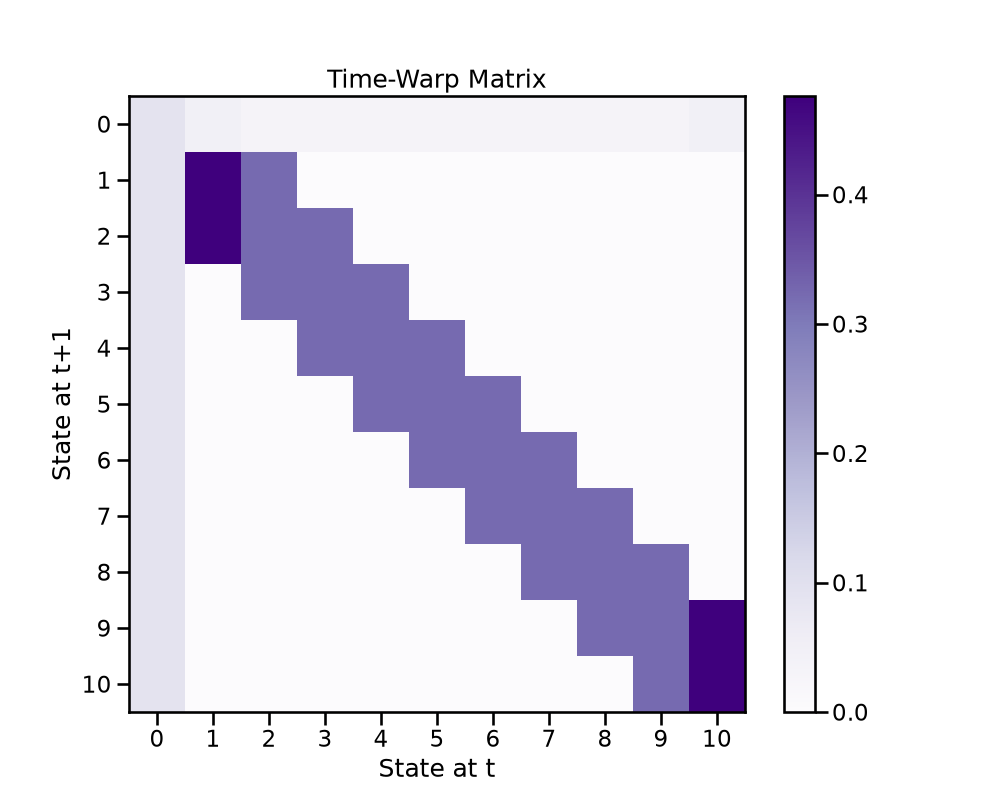

In [51]:
# preallocate time-warp matrix
H = np.zeros((S, S))

# get the time-warp values
s = np.linspace(0, 1, S)
print(s)

# give the time-warp a random walk structure
for i in range(S):
    for j in range(S):
        if abs(i - j) <= 1:
            H[i, j] = 1

# set first row and column
H[0, :] = .1
H[:, 0] = .1

# normalize rows
H = H / H.sum(axis=0, keepdims=True)


# visualize time-warp matrix
plt.figure(figsize=(10, 8))

plt.title("Time-Warp Matrix")

plt.imshow(H, cmap="Purples")
plt.colorbar()

plt.xticks(np.arange(S))
plt.yticks(np.arange(S))

plt.xlabel("State at t")
plt.ylabel("State at t+1")

plt.show()

## Transition Tensor

In [6]:
# generate the transition tensor
transitionTensor = np.zeros((M, M, S))
for w in range(S):
    transitionTensor[:, :, w] = (1 - s[w]) * np.eye(M) + s[w] * T_star


## Initial Probability distribution

In [7]:
# uniform initialization of the initial state distribution
pi = np.ones((M,S)) / (M * S)

pi_marg_z = np.sum(pi, axis=1)
pi_marg_tau = np.sum(pi, axis=0)

## Simulating the Sequential Time-Warping Hidden Markov Model

In [8]:
T = 10_000  # length of the observation sequence

observations = np.zeros((T, N))  # preallocate observation matrix
taus = np.zeros(T)  # preallocate time-warp sequence
Zs = np.zeros(T)  # preallocate hidden state sequence

# initialize the first hidden state and time-warp by sampling from the initial distributions pi
Zs[0] = np.random.choice(M, p=pi_marg_z)
taus[0] = np.random.choice(S, p=pi_marg_tau)
for n in range(N):
    observations[0, n] = np.random.poisson(lam=Lambda[n, int(Zs[0])])


# generate the rest of the hidden state and time-warp sequences
for t in tqdm(range(1, T)):
    Zs[t] = np.random.choice(M, p=transitionTensor[:, int(Zs[t-1]), int(taus[t-1])])
    taus[t] = np.random.choice(S, p=H[:, int(taus[t-1])])
    for n in range(N):
        observations[t, n] = np.random.poisson(lam=Lambda[n, int(Zs[t])])





100%|██████████| 9999/9999 [00:00<00:00, 12659.04it/s]


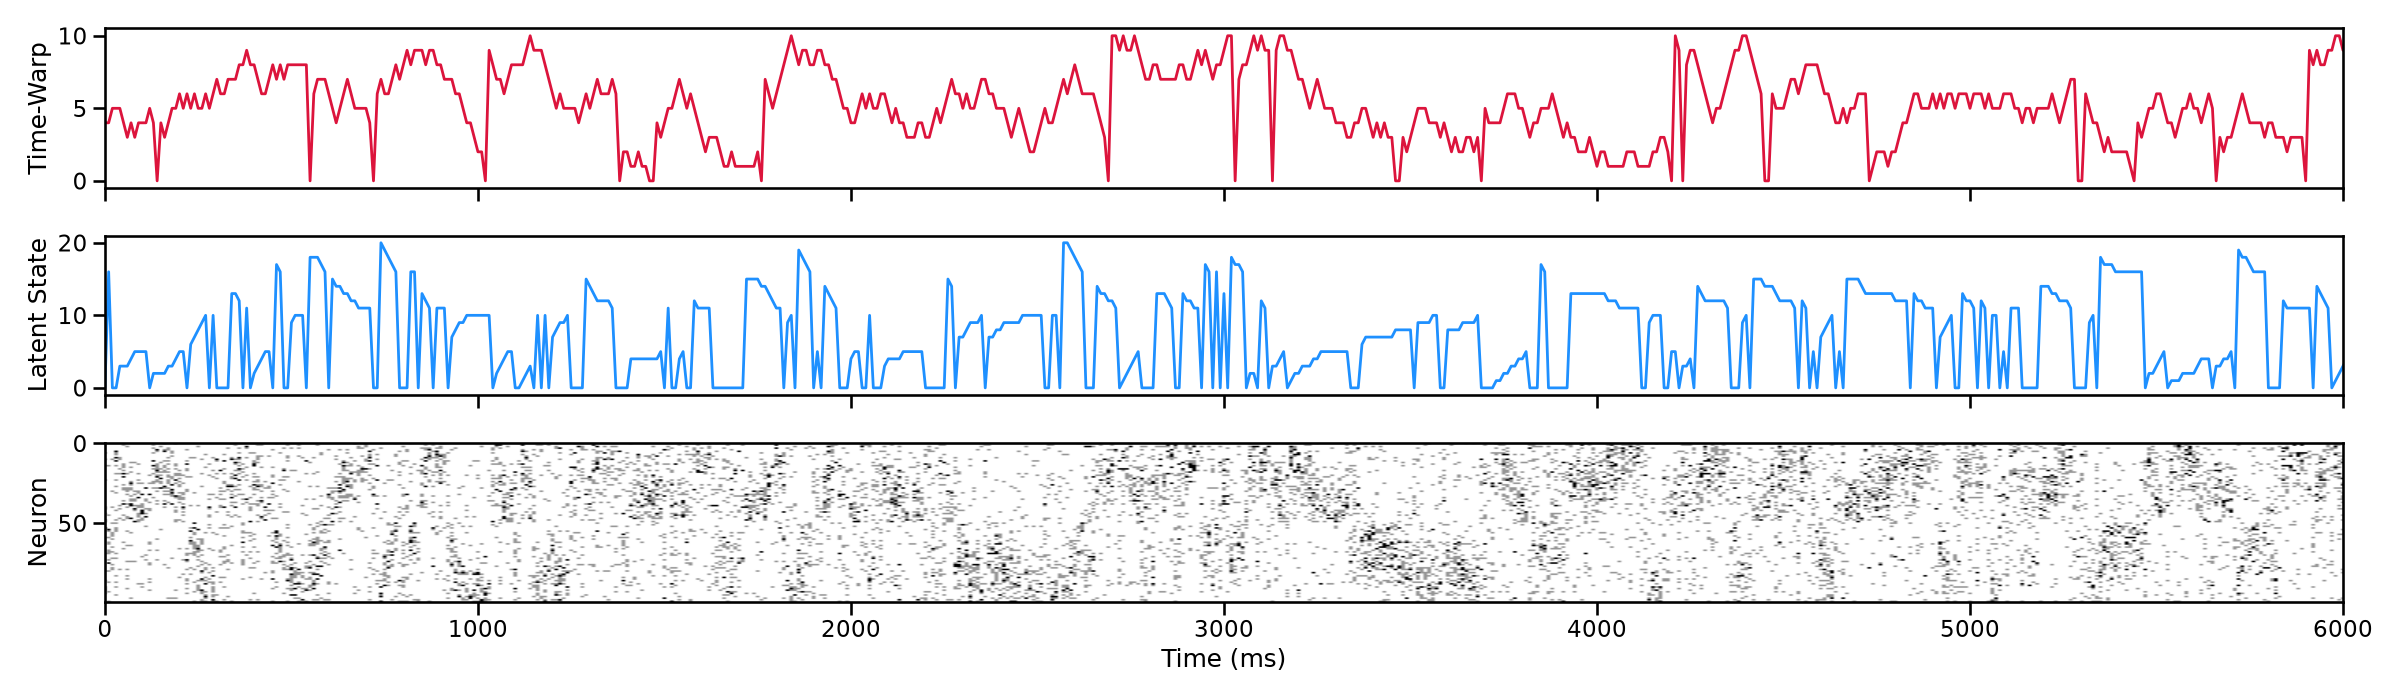

In [59]:


# plot the time-warp, latent state sequence and observations
fig, axs = plt.subplots(3, 1, figsize=(24, 7), sharex = True)

axs[0].plot(taus, linewidth=2, color = 'crimson')
#axs[0].set_title("Time-Warp Trajectory")
axs[0].set_ylabel("Time-Warp")



axs[1].plot(Zs, linewidth=2, color = 'dodgerblue')
#axs[1].set_title("Latent State Trajectory")
axs[1].set_ylabel("Latent State")




# plot the emissions as a heatmap 
im = axs[2].imshow(observations.T, aspect='auto', cmap='Greys', vmin = 0, vmax = 2)
#axs[2].set_title("Observations (spike counts)")
axs[2].set_xlabel("Time (ms)")
axs[2].set_ylabel("Neuron")

# cahnge the x ticks so that they are all divided by 20
axs[2].set_xticks(np.arange(6000, 6601, 100))
axs[2].set_xticklabels(np.arange(0, 601, 100) * 10)

# set x ticks so each time bin is 20 ms
#axs[2].set_xticks(np.linspace(0, T, 11))
#axs[2].set_xticklabels(np.linspace(0, T* 10, 11))

axs[2].set_xlim(6000, 6600)
plt.tight_layout()
plt.show()

# Model Recovery

### Helper Functions

In [10]:
import numpy as np
from scipy.special import gammaln, logsumexp


def log_poisson(y: np.ndarray, log_rate: np.ndarray) -> np.ndarray:
    """
    Log probability of independent Poisson observations.

    Parameters
    ----------
    y : (..., N) array
        Observed spike counts.
    log_rate : (..., N) array
        Log Poisson rates.

    Returns
    -------
    log_prob : (...) array
        Sum of log probabilities across neurons.
    """
    y = np.asarray(y)
    log_rate = np.asarray(log_rate)

    # y * log(lambda), with 0 * (-inf) defined as 0
    y_log_rate = np.zeros(np.broadcast_shapes(y.shape, log_rate.shape))
    np.multiply(y, log_rate, out=y_log_rate, where=(y != 0))

    return np.sum(
        y_log_rate - np.exp(log_rate) - gammaln(y + 1),
        axis=-1
    )


def compute_log_emissions(
    Y: np.ndarray,
    log_Lambda: np.ndarray
) -> np.ndarray:
    """
    Compute log p(y_t | z_t=m) for every time and latent state.

    Returns
    -------
    log_B : (T, M) array
        log_B[t, m] = log p(y_t | z_t=m)
    """
    return log_poisson(
        Y[:, None, :],
        log_Lambda[None, :, :]
    )


def compute_log_alpha(
    Y: np.ndarray,
    log_Lambda: np.ndarray,
    log_P: np.ndarray,
    log_pi: np.ndarray
) -> np.ndarray:
    """
    Compute log forward probabilities.

    log_P[i, j, l, w] =
        log p(z_{t+1}=i, tau_{t+1}=j | z_t=l, tau_t=w)

    Returns
    -------
    log_alpha : (M, S, T) array
    """
    T = Y.shape[0]
    M, S = log_pi.shape

    log_B = compute_log_emissions(Y, log_Lambda)
    log_alpha = np.full((M, S, T), -np.inf)

    # t = 0
    log_alpha[:, :, 0] = (
        log_pi + log_B[0, :, None]
    )

    # t = 1, ..., T-1
    for t in range(1, T):

        # Shape:
        # log_P             -> (next_z, next_tau, current_z, current_tau)
        # previous alpha    ->                         (current_z, current_tau)

        transition_scores = (
            log_P +
            log_alpha[None, None, :, :, t - 1]
        )

        log_alpha[:, :, t] = (
            log_B[t, :, None] +
            logsumexp(transition_scores, axis=(2, 3))
        )

    return log_alpha


def compute_log_beta(
    Y: np.ndarray,
    log_Lambda: np.ndarray,
    log_P: np.ndarray
) -> np.ndarray:
    """
    Compute log backward probabilities.

    Returns
    -------
    log_beta : (M, S, T) array
    """
    T = Y.shape[0]
    M, S = log_P.shape[:2]

    log_B = compute_log_emissions(Y, log_Lambda)
    log_beta = np.full((M, S, T), -np.inf)

    # beta_T(i,j) = 1  ->  log beta_T(i,j) = 0
    log_beta[:, :, -1] = 0.0

    for t in range(T - 2, -1, -1):

        # Score associated with each possible NEXT state pair (i,j)
        next_scores = (
            log_beta[:, :, t + 1] +
            log_B[t + 1, :, None]
        )

        # P dimensions:
        # (next_z, next_tau, current_z, current_tau)
        log_beta[:, :, t] = logsumexp(
            log_P +
            next_scores[:, :, None, None],
            axis=(0, 1)
        )

    return log_beta


def compute_log_viterbi(
    Y: np.ndarray,
    log_Lambda: np.ndarray,
    log_P: np.ndarray,
    log_pi: np.ndarray
):
    """
    Run Viterbi decoding.

    Returns
    -------
    log_viterbi : (M, S, T)
    back_pointer : (M, S, T, 2)

    back_pointer[i,j,t] contains the previous (z, tau) pair.
    """
    T = Y.shape[0]
    M, S = log_pi.shape

    log_B = compute_log_emissions(Y, log_Lambda)

    log_viterbi = np.full((M, S, T), -np.inf)
    back_pointer = np.full((M, S, T, 2), -1, dtype=int)

    # Initialization
    log_viterbi[:, :, 0] = (
        log_pi + log_B[0, :, None]
    )

    for t in range(1, T):
        for i in range(M):
            for j in range(S):

                scores = (
                    log_viterbi[:, :, t - 1] +
                    log_P[i, j, :, :]
                )

                flat_index = np.argmax(scores)
                previous_state = np.unravel_index(
                    flat_index,
                    (M, S)
                )

                back_pointer[i, j, t] = previous_state

                log_viterbi[i, j, t] = (
                    log_B[t, i] +
                    scores[previous_state]
                )

    return log_viterbi, back_pointer


def get_state_sequence(
    log_viterbi: np.ndarray,
    back_pointer: np.ndarray
) -> np.ndarray:
    """
    Recover the MAP sequence of joint latent states.

    Returns
    -------
    states : (2, T) array

        states[0, t] = z_t
        states[1, t] = tau_t
    """
    M, S, T = log_viterbi.shape

    states = np.zeros((2, T), dtype=int)

    # Best terminal state
    states[:, -1] = np.unravel_index(
        np.argmax(log_viterbi[:, :, -1]),
        (M, S)
    )

    # Backtrack
    for t in range(T - 2, -1, -1):

        next_z = states[0, t + 1]
        next_tau = states[1, t + 1]

        states[:, t] = back_pointer[
            next_z,
            next_tau,
            t + 1
        ]

    return states


def compute_log_zeta(
    Y: np.ndarray,
    log_Lambda: np.ndarray,
    log_P: np.ndarray,
    log_alpha: np.ndarray,
    log_beta: np.ndarray
) -> np.ndarray:
    """
    Compute posterior log probabilities of joint-state transitions.

    log_zeta[i,j,l,w,t] =
        log p(
            z_{t+1}=i,
            tau_{t+1}=j,
            z_t=l,
            tau_t=w
            | Y
        )
    """
    M, S, T = log_alpha.shape

    log_B = compute_log_emissions(Y, log_Lambda)

    log_zeta = np.full(
        (M, S, M, S, T - 1),
        -np.inf
    )

    # Sequence log likelihood
    log_likelihood = logsumexp(
        log_alpha[:, :, -1]
    )

    for t in range(T - 1):

        log_zeta[:, :, :, :, t] = (
            log_alpha[None, None, :, :, t]
            + log_P
            + log_B[t + 1, :, None, None, None]
            + log_beta[:, :, None, None, t + 1]
            - log_likelihood
        )

    return log_zeta


def compute_log_gamma(
    log_alpha: np.ndarray,
    log_beta: np.ndarray
) -> np.ndarray:
    """
    Posterior probability over joint states (z_t, tau_t).

    Returns
    -------
    log_gamma_joint : (M, S, T)
    """
    log_gamma_joint = log_alpha + log_beta

    # Normalize independently at every time point
    log_gamma_joint -= logsumexp(
        log_gamma_joint,
        axis=(0, 1),
        keepdims=True
    )

    return log_gamma_joint


def compute_log_gamma_z(
    log_alpha: np.ndarray,
    log_beta: np.ndarray
) -> np.ndarray:
    """
    Posterior log probability of z_t after marginalizing tau.

    Returns
    -------
    log_gamma_z : (M, T)
    """
    log_gamma_joint = compute_log_gamma(
        log_alpha,
        log_beta
    )

    return logsumexp(
        log_gamma_joint,
        axis=1
    )


def build_log_master_tensor(
    log_T: np.ndarray,
    log_H: np.ndarray,
    s: np.ndarray
) -> np.ndarray:
    """
    Construct the log master transition tensor.

    P[i, j, l, w] =
        p(z_{t+1}=i, tau_{t+1}=j |
          z_t=l, tau_t=w)

    where

        P[i,j,l,w]
        = H[j,w] *
          ((1-s[w]) * I[i,l] + s[w] * T*[i,l])

    Parameters
    ----------
    log_T : (M, M)
        Log transition matrix for z.

    log_H : (S, S)
        Log transition matrix for tau.

    s : (S,)
        Time-warp values.

    Returns
    -------
    log_P : (M, S, M, S)
        Log master transition tensor.
    """

    M = log_T.shape[0]
    S = log_H.shape[0]

    T = np.exp(log_T)
    H = np.exp(log_H)

    I = np.eye(M)

    log_P = np.full(
        (M, S, M, S),
        -np.inf
    )

    for w in range(S):

        # z-transition matrix conditional on current tau=w
        warped_T = (
            (1.0 - s[w]) * I
            + s[w] * T
        )

        for j in range(S):

            P_slice = H[j, w] * warped_T

            with np.errstate(divide="ignore"):
                log_P[:, j, :, w] = np.log(P_slice)

    return log_P

    """
    Construct mask of allowed transitions in T*.

    Convention
    ----------
    mask[next_state, current_state]

    State 0 is the hub state.
    """
    mask = np.zeros((M, M), dtype=bool)

    # Hub -> sequence states
    mask[1:, 0] = True

    # Sequence states -> hub
    mask[0, 1:] = True

    half = M // 2

    # Forward sequence:
    # 1 -> 2 -> 3 -> ...
    for current in range(1, half):
        next_state = current + 1

        if next_state < half:
            mask[next_state, current] = True

    # Reverse sequence:
    # M-1 -> M-2 -> ...
    for current in range(M - 1, half, -1):
        next_state = current - 1
        mask[next_state, current] = True

    return mask

### Initialization

In [11]:

def initialize_log_Lambda(
    Y: np.ndarray,
    M: int,
    clone_groups,
    sigma: float = 0.25
) -> np.ndarray:
    """
    Initialize Poisson emission rates while enforcing
    shared emissions among cloned latent states.
    """

    N = Y.shape[1]

    # Empirical mean firing rate for each neuron
    mean_rates = Y.mean(axis=0)

    # Prevent exact zeros
    mean_rates = np.maximum(mean_rates, 1e-12)

    Lambda = np.zeros((M, N))

    for group in clone_groups:

        # Generate ONE emission vector for the entire clone group
        group_rate = (
            mean_rates *
            np.random.lognormal(
                mean=0.0,
                sigma=sigma,
                size=N
            )
        )

        # Assign exactly the same emissions to every clone
        for m in group:
            Lambda[m, :] = group_rate

    Lambda = np.maximum(Lambda, 1e-12)

    return np.log(Lambda)



def get_clone_groups(M: int):
    """
    Return groups of latent states that share emission parameters.

    State 0 is the hub and has its own emission parameters.

    The first half of the non-hub states are the forward states.
    The second half are their reverse clones.

    For M = 21:

        forward states:  1,  2, ..., 10
        reverse clones: 11, 12, ..., 20

        clone pairs:
            [1, 11]
            [2, 12]
            ...
            [10, 20]

    Parameters
    ----------
    M : int
        Total number of latent states, including the hub.

    Returns
    -------
    clone_groups : list[list[int]]
        Groups of states constrained to share emissions.
    """

    # There must be one hub plus an even number
    # of non-hub states.
    if (M - 1) % 2 != 0:
        raise ValueError(
            "M must contain one hub state plus an even "
            "number of sequence states."
        )

    # Number of forward states = number of reverse clones
    nForward = (M - 1) // 2

    # Hub has its own emission parameters
    clone_groups = [[0]]

    # Pair each forward state with its reverse clone
    for state in range(1, nForward + 1):

        reverse_clone = state + nForward

        clone_groups.append(
            [state, reverse_clone]
        )

    return clone_groups


def get_T_mask(M: int) -> np.ndarray:
    """
    Construct mask of allowed transitions in T*.

    Convention
    ----------
    mask[next_state, current_state]

    State 0 is the hub state.
    """
    mask = np.zeros((M, M), dtype=bool)

    # Hub -> sequence states
    mask[1:, 0] = True

    # Sequence states -> hub
    mask[0, 1:] = True

    half = M // 2

    # Forward sequence:
    # 1 -> 2 -> 3 -> ...
    for current in range(1, half):
        next_state = current + 1

        if next_state < half:
            mask[next_state, current] = True

    # Reverse sequence:
    # M-1 -> M-2 -> ...
    for current in range(M - 1, half, -1):
        next_state = current - 1
        mask[next_state, current] = True

    return mask

### Expectation Maximization Functions

In [12]:


def update_log_T(
    log_zeta: np.ndarray,
    T_mask: np.ndarray
) -> np.ndarray:
    """
    M-step update for log T*.

    T*[i,j] = p(z_{t+1}=i | z_t=j)

    T_mask[i,j] is True for allowed transitions.
    """
    M = log_zeta.shape[0]

    # log_xi[i,l]
    # Sum over:
    #   next tau
    #   current tau
    #   time
    log_xi = logsumexp(
        log_zeta,
        axis=(1, 3, 4)
    )

    # Enforce structural zeros
    log_xi = np.where(T_mask, log_xi, -np.inf)

    # Normalize over possible NEXT z states,
    # separately for each CURRENT z state.
    log_denominator = logsumexp(
        log_xi,
        axis=0,
        keepdims=True
    )

    log_T = log_xi - log_denominator

    # Reapply mask explicitly
    log_T[~T_mask] = -np.inf

    return log_T

def update_log_H(
    log_zeta: np.ndarray
) -> np.ndarray:
    """
    M-step update for the time-warp transition matrix.

    H[j,w] = p(tau_{t+1}=j | tau_t=w)
    """

    # Sum over:
    #   next z
    #   current z
    #   time
    #
    # Result has dimensions:
    #   (next_tau, current_tau)
    log_phi = logsumexp(
        log_zeta,
        axis=(0, 2, 4)
    )

    # Normalize possible next tau states
    # for each current tau state.
    log_H = (
        log_phi -
        logsumexp(log_phi, axis=0, keepdims=True)
    )

    return log_H


def update_log_Lambda(
    Y: np.ndarray,
    log_alpha: np.ndarray,
    log_beta: np.ndarray,
    clone_groups
) -> np.ndarray:
    """
    M-step update for Poisson emission rates with shared
    emissions among cloned latent states.

    All states belonging to the same clone group receive
    exactly the same emission-rate vector.

    Parameters
    ----------
    Y : (T, N)
        Observed spike counts.

    log_alpha : (M, S, T)
        Log forward probabilities.

    log_beta : (M, S, T)
        Log backward probabilities.

    clone_groups : list[list[int]]
        Groups of latent states constrained to share emissions.

        Example:
            [[0], [1, 20], [2, 19], ..., [10, 11]]

    Returns
    -------
    log_Lambda : (M, N)
        Updated log Poisson emission rates.
    """

    M = log_alpha.shape[0]
    N = Y.shape[1]

    # --------------------------------------------------------
    # Joint posterior:
    #
    # gamma_joint[m,s,t]
    #   = p(z_t=m, tau_t=s | Y)
    # --------------------------------------------------------

    log_gamma_joint = compute_log_gamma(
        log_alpha,
        log_beta
    )


    # --------------------------------------------------------
    # Marginalize over tau:
    #
    # gamma_z[m,t] = p(z_t=m | Y)
    # --------------------------------------------------------

    log_gamma_z = logsumexp(
        log_gamma_joint,
        axis=1
    )

    gamma_z = np.exp(log_gamma_z)


    # --------------------------------------------------------
    # Update emissions subject to clone constraint
    # --------------------------------------------------------

    Lambda = np.zeros((M, N))

    for group in clone_groups:

        # Pool posterior occupancy across all states
        # sharing this emission vector.
        group_gamma = gamma_z[group, :].sum(axis=0)

        # Effective posterior occupancy of this clone group
        denominator = group_gamma.sum()

        if denominator <= 0:
            raise RuntimeError(
                f"Clone group {group} has zero posterior occupancy."
            )

        # Weighted mean spike counts
        group_Lambda = (
            group_gamma @ Y
        ) / denominator

        # Assign the SAME rate vector to every clone
        for m in group:
            Lambda[m, :] = group_Lambda


    # Avoid log(0)
    Lambda = np.maximum(Lambda, 1e-12)

    return np.log(Lambda)

In [13]:
# number of iterations of random initialization
nIters = 100
num_EM_steps = 10
all_losses = np.zeros((nIters, num_EM_steps))

model_params = []

Y = observations
T_obs, N = Y.shape
all_state_sequences = np.zeros((nIters, 2, T_obs), dtype=int)  # preallocate state sequences (z, tau)

s = np.linspace(0.0, 1.0, S)

for iter in range(nIters):
    print(f"Iteration {iter+1}/{nIters}")




    # ------------------------------------------------------------
    # Initialize T*
    #
    # Convention:
    # T[i, l] = p(z_{t+1}=i | z_t=l)
    #
    # Therefore each COLUMN must sum to 1.
    # ------------------------------------------------------------

    T_mask = get_T_mask(M)

    T = np.zeros((M, M), dtype=float)
    T[T_mask] = np.random.rand(T_mask.sum())

    # Normalize each current-state column over its allowed
    # next states.
    T /= T.sum(axis=0, keepdims=True)

    # Convert to log-space.
    # Structurally impossible transitions become -inf.
    with np.errstate(divide="ignore"):
        log_T = np.log(T)


    # ------------------------------------------------------------
    # Initialize H
    #
    # H[j, w] = p(tau_{t+1}=j | tau_t=w)
    #
    # Again, each COLUMN corresponds to a current state and
    # must sum to 1.
    # ------------------------------------------------------------

    H = np.random.rand(S, S)
    H /= H.sum(axis=0, keepdims=True)

    log_H = np.log(H)


    # ------------------------------------------------------------
    # Initialize Poisson emission rates
    #
    # Lambda[m, n] = rate of neuron n in latent state m.
    #
    # These are rates, not probabilities, so they should NOT
    # be normalized.
    # ------------------------------------------------------------


    clone_groups = get_clone_groups(M, )

    log_Lambda = initialize_log_Lambda(
        Y,
        M,
        clone_groups
    )


    # ------------------------------------------------------------
    # Initialize joint initial-state distribution
    #
    # pi[m, s] = p(z_1=m, tau_1=s)
    # ------------------------------------------------------------

    pi = np.random.rand(M, S)
    pi /= pi.sum()

    log_pi = np.log(pi)




    # ------------------------------------------------------------
    # Initialize the master tensor
    #
    # P[i, j, l, w] = p(z_{t+1}=i, tau_{t+1}=j | z_t=l, tau_t=w)
    #-------------------------------------------------------------

    log_P = build_log_master_tensor(
        log_T,
        log_H,
        s
    )

    # ============================================================
    # INITIALIZATION CHECKS
    # ============================================================

    # T*: each current-state column sums to 1
    assert np.allclose(
        np.exp(log_T).sum(axis=0),
        1.0,
        atol=1e-10
    )

    # H: each current-state column sums to 1
    assert np.allclose(
        np.exp(log_H).sum(axis=0),
        1.0,
        atol=1e-10
    )

    # pi: entire joint initial distribution sums to 1
    assert np.allclose(
        np.exp(log_pi).sum(),
        1.0,
        atol=1e-10
    )

    # P: for every current (z, tau), all possible
    # next joint states must sum to 1.
    P = np.exp(log_P)

    assert np.allclose(
        P.sum(axis=(0, 1)),
        1.0,
        atol=1e-10
    )

    print("Initialization checks passed.")

    # ============================================================
    # VISUALIZE INITIAL PARAMETERS
    # ============================================================

    fig, axs = plt.subplots(1, 3, figsize=(15, 5))


    # ------------------------------------------------------------
    # T*
    # ------------------------------------------------------------

    axs[0].imshow(
        np.exp(log_T),
        aspect="auto",
        cmap="Blues"
    )

    axs[0].set_title(r"$T^*$")
    axs[0].set_xlabel("Current state")
    axs[0].set_ylabel("Next state")


    # ------------------------------------------------------------
    # H
    # ------------------------------------------------------------

    axs[1].imshow(
        np.exp(log_H),
        aspect="auto",
        cmap="Purples"
    )

    axs[1].set_title(r"$H$")
    axs[1].set_xlabel(r"Current $\tau$")
    axs[1].set_ylabel(r"Next $\tau$")


    # ------------------------------------------------------------
    # Lambda
    #
    # Lambda has shape:
    #     (latent state, neuron)
    #
    # Find the latent state at which EACH NEURON has its
    # maximum firing rate.
    # ------------------------------------------------------------

    Lambda = np.exp(log_Lambda)

    peak_state = np.argmax(
        Lambda,
        axis=0
    )

    # Sort NEURONS according to their preferred latent state
    neuron_order = np.argsort(peak_state)

    # Keep latent states in their original order.
    # Only reorder neurons.
    Lambda_sorted = Lambda[:, neuron_order]


    # Plot:
    # rows    = neurons
    # columns = latent states
    axs[2].imshow(
        Lambda_sorted.T,
        aspect="auto",
        cmap="Reds"
    )

    axs[2].set_title(r"$\Lambda$")
    axs[2].set_xlabel("Latent state")
    axs[2].set_ylabel("Neuron")


    plt.tight_layout()
    plt.savefig(f"initial_parameters_{iter}.png")
    plt.close()


    # ============================================================
    # EM FITTING
    # ============================================================

    num_iterations = 20

    losses = []
    log_likelihoods = []


    for step in range(num_EM_steps):

        # ========================================================
        # E STEP
        # ========================================================

        log_alpha = compute_log_alpha(
            Y,
            log_Lambda,
            log_P,
            log_pi
        )

        log_beta = compute_log_beta(
            Y,
            log_Lambda,
            log_P
        )

        log_zeta = compute_log_zeta(
            Y,
            log_Lambda,
            log_P,
            log_alpha,
            log_beta
        )

        log_gamma = compute_log_gamma(
            log_alpha,
            log_beta
        )


        # ========================================================
        # COMPUTE OBSERVED-DATA LOG LIKELIHOOD
        # ========================================================

        log_likelihood = logsumexp(
            log_alpha[:, :, -1]
        )

        loss = -log_likelihood

        log_likelihoods.append(log_likelihood)
        losses.append(loss)


        # ========================================================
        # DEBUGGING / CONSISTENCY TESTS
        # ========================================================

        # --------------------------------------------------------
        # Test 1:
        # Forward-backward likelihood identity
        #
        # For every t:
        #
        # sum_{i,j} alpha_t(i,j) beta_t(i,j) = p(Y)
        #
        # Therefore in log-space:
        #
        # LSE(log_alpha_t + log_beta_t) = log p(Y)
        # --------------------------------------------------------

        for t in range(T_obs):

            fb_log_likelihood = logsumexp(
                log_alpha[:, :, t]
                + log_beta[:, :, t]
            )

            if not np.allclose(
                fb_log_likelihood,
                log_likelihood,
                atol=1e-8
            ):
                raise RuntimeError(
                    f"Forward-backward likelihood mismatch "
                    f"at iteration {step}, time {t}: "
                    f"{fb_log_likelihood:.12f} vs "
                    f"{log_likelihood:.12f}"
                )

        # --------------------------------------------------------
        # Test zeta normalization
        # --------------------------------------------------------

        zeta_norms = np.array([
            logsumexp(log_zeta[..., t])
            for t in range(T_obs - 1)
        ])

        max_zeta_error = np.max(
            np.abs(zeta_norms)
        )

        if max_zeta_error > 1e-6:

            worst_t = np.argmax(
                np.abs(zeta_norms)
            )

            raise RuntimeError(
                f"Zeta normalization failed at iteration {step}. "
                f"Worst time = {worst_t}, "
                f"logsumexp = {zeta_norms[worst_t]:.12e}"
            )


        
        # --------------------------------------------------------
        # Test 3:
        # gamma must sum to 1 at every time point.
        # --------------------------------------------------------

        gamma_norm = logsumexp(
            log_gamma,
            axis=(0, 1)
        )

        if not np.allclose(
            gamma_norm,
            0.0,
            atol=1e-8
        ):
            raise RuntimeError(
                f"Gamma normalization failed "
                f"at iteration {step}."
            )


        # --------------------------------------------------------
        # Test 4:
        # Test emission clone constraint
        # --------------------------------------------------------

        for group in clone_groups:

            reference = log_Lambda[group[0], :]

            for m in group[1:]:

                if not np.allclose(
                    log_Lambda[m, :],
                    reference,
                    atol=1e-12
                ):
                    raise RuntimeError(
                        f"Shared-emission constraint failed "
                        f"for clone group {group} "
                        f"after iteration {step}."
                    )


        # ========================================================
        # M STEP
        # ========================================================

        log_T = update_log_T(
            log_zeta,
            T_mask
        )

        log_H = update_log_H(
            log_zeta
        )

        log_Lambda = update_log_Lambda(
            Y,
            log_alpha,
            log_beta,
            clone_groups
        )


        # ========================================================
        # REBUILD MASTER TRANSITION TENSOR
        # ========================================================

        log_P = build_log_master_tensor(
            log_T,
            log_H,
            s
        )


        # ========================================================
        # CHECK UPDATED TRANSITION MATRICES
        # ========================================================

        if not np.allclose(
            np.exp(log_T).sum(axis=0),
            1.0,
            atol=1e-8
        ):
            raise RuntimeError(
                f"T* normalization failed "
                f"after iteration {step}."
            )

        if not np.allclose(
            np.exp(log_H).sum(axis=0),
            1.0,
            atol=1e-8
        ):
            raise RuntimeError(
                f"H normalization failed "
                f"after iteration {step}."
                f"after iteration {step}."
            )

        if not np.allclose(
            np.exp(log_P).sum(axis=(0, 1)),
            1.0,
            atol=1e-8
        ):
            raise RuntimeError(
                f"Master tensor normalization failed "
                f"after iteration {step}."
            )


    # ============================================================
    # SAVE MODEL PARAMS
    # ============================================================

    model_params.append(
        {
            "log_T": log_T,
            "log_H": log_H,
            "log_Lambda": log_Lambda
        }
    )

    # ============================================================
    # PLOT EM CONVERGENCE
    # ============================================================

    plt.figure(figsize=(7, 5))

    plt.plot(
        np.arange(1, num_EM_steps + 1),
        losses,
        linewidth = 3
    )

    plt.xlabel("EM iteration")
    plt.ylabel("Negative log-likelihood")
    plt.title("STWHMM EM convergence")

    plt.tight_layout()
    plt.savefig(f"em_convergence_{iter}.png")
    plt.close()

    # append to the list of losses for plotting EM convergence
    all_losses[iter, :] = losses


    # ============================================================
    # PLOT FITTED MATRICES
    # ============================================================

    fig, axs = plt.subplots(1, 3, figsize=(15, 5))


    # ------------------------------------------------------------
    # T*
    # ------------------------------------------------------------

    axs[0].imshow(
        np.exp(log_T),
        aspect="auto"
    )

    axs[0].set_title(r"$T^*$")
    axs[0].set_xlabel("Current state")
    axs[0].set_ylabel("Next state")


    # ------------------------------------------------------------
    # H
    # ------------------------------------------------------------

    axs[1].imshow(
        np.exp(log_H),
        aspect="auto"
    )

    axs[1].set_title(r"$H$")
    axs[1].set_xlabel(r"Current $\tau$")
    axs[1].set_ylabel(r"Next $\tau$")


    # ------------------------------------------------------------
    # Lambda
    #
    # Lambda has shape:
    #     (latent state, neuron)
    #
    # Find the latent state at which EACH NEURON has its
    # maximum firing rate.
    # ------------------------------------------------------------

    Lambda = np.exp(log_Lambda)

    peak_state = np.argmax(
        Lambda,
        axis=0
    )

    # Sort NEURONS according to their preferred latent state
    neuron_order = np.argsort(peak_state)

    # Keep latent states in their original order.
    # Only reorder neurons.
    Lambda_sorted = Lambda[:, neuron_order]


    # Plot:
    # rows    = neurons
    # columns = latent states
    axs[2].imshow(
        Lambda_sorted.T,
        aspect="auto"
    )

    axs[2].set_title(r"$\Lambda$")
    axs[2].set_xlabel("Latent state")
    axs[2].set_ylabel("Neuron")


    plt.tight_layout()
    plt.savefig(f"fitted_matrices_{iter}.png")
    plt.close()

    # run viterbi to find the most likely sequence of hidden states
    log_viterbi, back_pointers = compute_log_viterbi(
        Y,
        log_Lambda,
        log_P,
        log_pi
    )

    state_sequence = get_state_sequence(log_viterbi, back_pointers)

    all_state_sequences[iter, :, :] = state_sequence

Iteration 1/100
Initialization checks passed.
Iteration 2/100
Initialization checks passed.
Iteration 3/100
Initialization checks passed.
Iteration 4/100
Initialization checks passed.
Iteration 5/100
Initialization checks passed.
Iteration 6/100
Initialization checks passed.
Iteration 7/100
Initialization checks passed.
Iteration 8/100
Initialization checks passed.
Iteration 9/100
Initialization checks passed.
Iteration 10/100
Initialization checks passed.
Iteration 11/100
Initialization checks passed.
Iteration 12/100
Initialization checks passed.
Iteration 13/100
Initialization checks passed.
Iteration 14/100
Initialization checks passed.
Iteration 15/100
Initialization checks passed.
Iteration 16/100
Initialization checks passed.
Iteration 17/100
Initialization checks passed.
Iteration 18/100
Initialization checks passed.
Iteration 19/100
Initialization checks passed.
Iteration 20/100
Initialization checks passed.
Iteration 21/100
Initialization checks passed.
Iteration 22/100
Initi

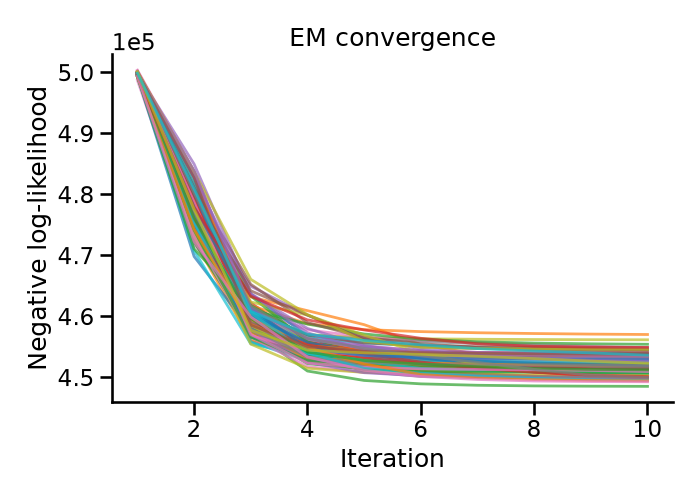

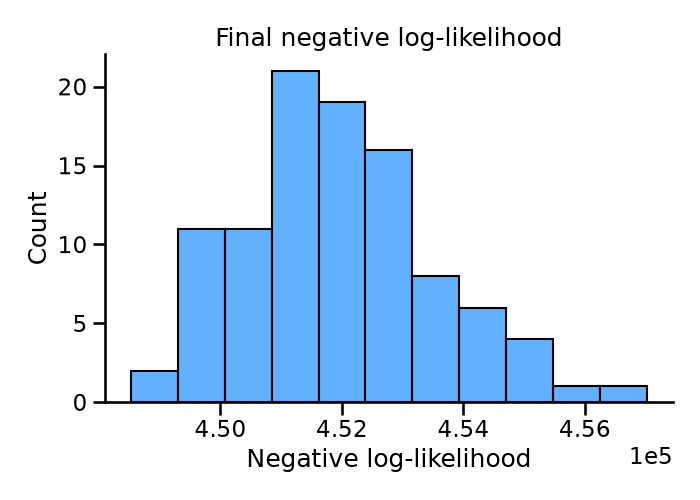

In [92]:
# plot all the likelihood curves
plt.figure(figsize=(7, 5))
for iter in range(all_losses.shape[0]):
    plt.plot(
        np.arange(1, all_losses.shape[1] + 1),
        all_losses[iter, :],
        linewidth=2,
        alpha=0.7
    )

plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.title("EM convergence")
plt.tight_layout()
sns.despine()
plt.show()

# plot the historgram of the final negative log-likelihood values
plt.figure(figsize=(7, 5))
sns.histplot(all_losses[:, -1], bins=11, alpha=0.7, stat = 'count', color='dodgerblue')
plt.xlabel("Negative log-likelihood")
plt.ylabel("Count")
plt.title("Final negative log-likelihood")
plt.ticklabel_format(axis='x', style='sci', scilimits=(0,0))
plt.tight_layout()
sns.despine()
plt.show()



Minimum loss index: 22


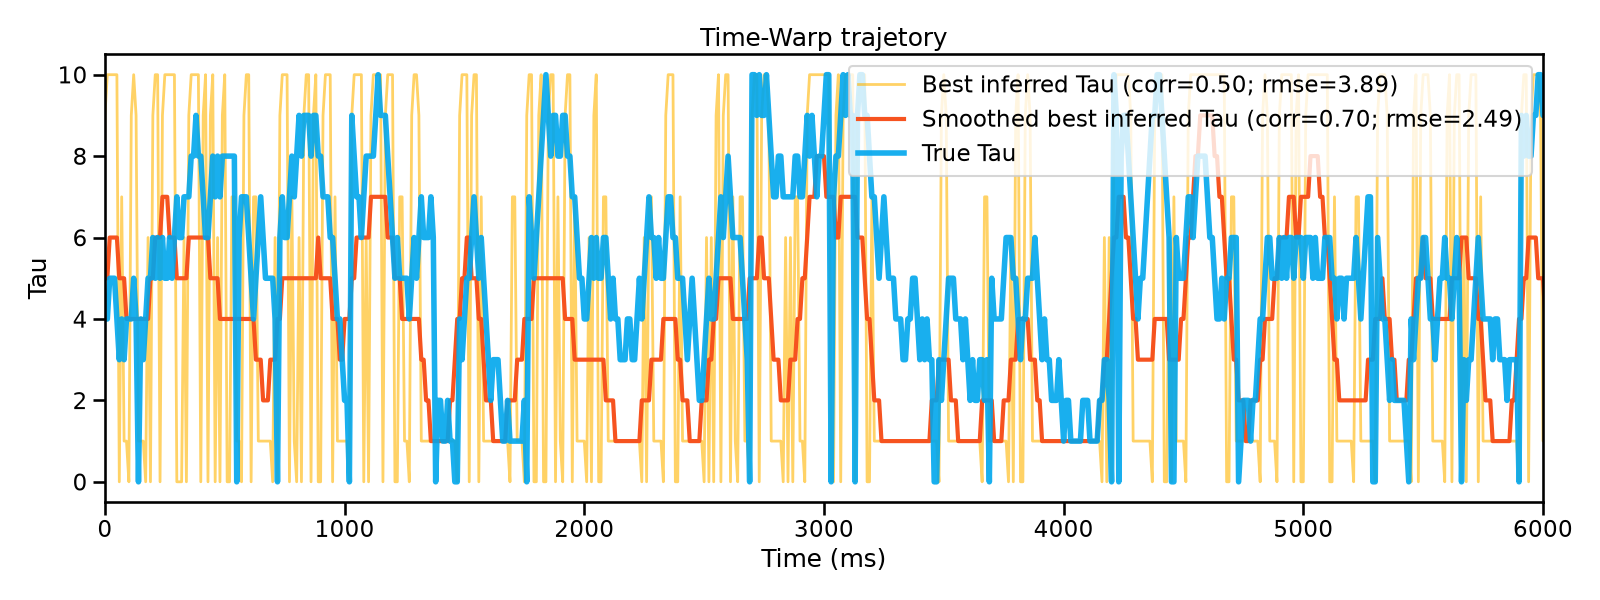

In [186]:
from scipy.ndimage import gaussian_filter1d

min_loss_index = np.argmin(all_losses[:, -1])
print("Minimum loss index:", min_loss_index)
best_tau_sequence = all_state_sequences[min_loss_index, 1, :]
mean_tau_sequence = all_state_sequences[:, 1, :].mean(axis=0)

# smooth the best tau sequence
best_tau_sequence_smoothed = gaussian_filter1d(best_tau_sequence, sigma=4)


best_tau_corr = np.corrcoef(best_tau_sequence, taus)[0, 1]
best_tau_mse = np.mean((best_tau_sequence - taus) ** 2)
best_tau_smooth_corr = np.corrcoef(best_tau_sequence_smoothed, taus)[0, 1]
best_tau_smooth_mse = np.mean((best_tau_sequence_smoothed - taus) ** 2)
best_tau_rmse = np.sqrt(best_tau_mse)
best_tau_smooth_rmse = np.sqrt(best_tau_smooth_mse)




# plot all the tau sequences and their mean
plt.figure(figsize =(16, 6))


plt.plot(best_tau_sequence, alpha=0.6, color='#ffb400', linewidth=2, label=f'Best inferred Tau (corr={best_tau_corr:.2f}; rmse={best_tau_rmse:.2f})')
plt.plot(best_tau_sequence_smoothed, alpha=0.99, color='#f6511d', linewidth=3, label=f'Smoothed best inferred Tau (corr={best_tau_smooth_corr:.2f}; rmse={best_tau_smooth_rmse:.2f})')
plt.plot(taus, label = 'True Tau', color='#00a6ed', linewidth=4, alpha = 0.9)
plt.title("Time-Warp trajetory")
plt.xlabel("Time (ms)")
plt.ylabel("Tau")
# cahnge the x ticks so that they are all divided by 20
plt.xticks(np.arange(6000, 6601, 100))
plt.gca().set_xticklabels(np.arange(0, 601, 100) * 10)


plt.xlim(6000, 6600)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:


# take the correlation of the mean inferred tau and the true tau
correlation = np.corrcoef(all_state_sequences[:, 1, :].mean(axis=0), taus)[0, 1]
print(f"Correlation between mean inferred tau and true tau: {correlation}")

# take the weighted mean of the inferred tau sequences weighting by the loss
final_losses = 1 / all_losses[:, -1]
#normalize 
final_losses = final_losses / final_losses.sum()
weighted_mean_tau = np.average(all_state_sequences[:, 1, :], axis=0, weights=final_losses)

# take the correlation of the weighted mean inferred tau and the true tau
weighted_correlation = np.corrcoef(weighted_mean_tau, taus)[0, 1]
print(f"Correlation between weighted mean inferred tau and true tau: {weighted_correlation}")


Correlation between mean inferred tau and true tau: 0.49286093008023246
Correlation between weighted mean inferred tau and true tau: 0.49298180607952347


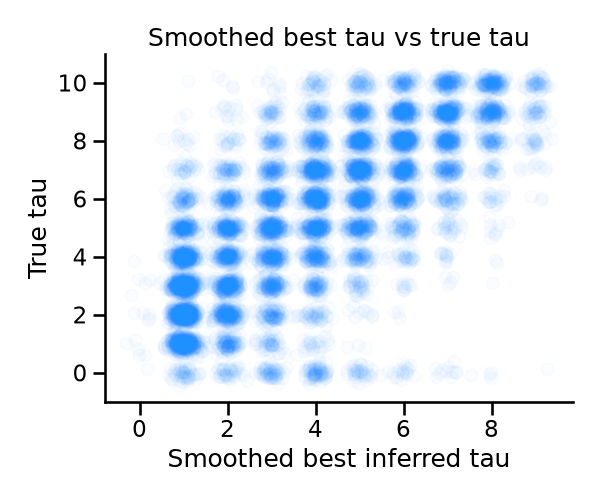

In [157]:
#scatterplot of the mean inferred tau vs the true tau
plt.figure(figsize=(6, 5))
plt.scatter(best_tau_sequence_smoothed + np.random.normal(0, 0.15, size=best_tau_sequence_smoothed.shape), taus + np.random.normal(0, 0.15, size=taus.shape), alpha=0.02, color = 'dodgerblue')
plt.xlabel("Smoothed best inferred tau")
plt.ylabel("True tau")
plt.title("Smoothed best tau vs true tau")
plt.tight_layout()
sns.despine()
plt.show()


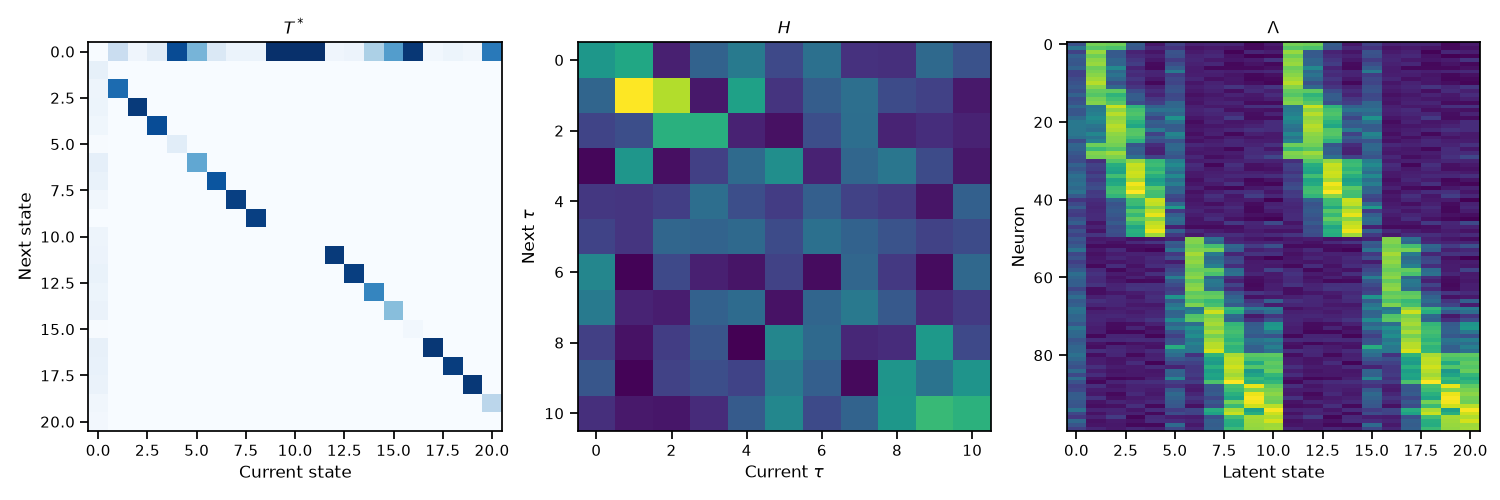

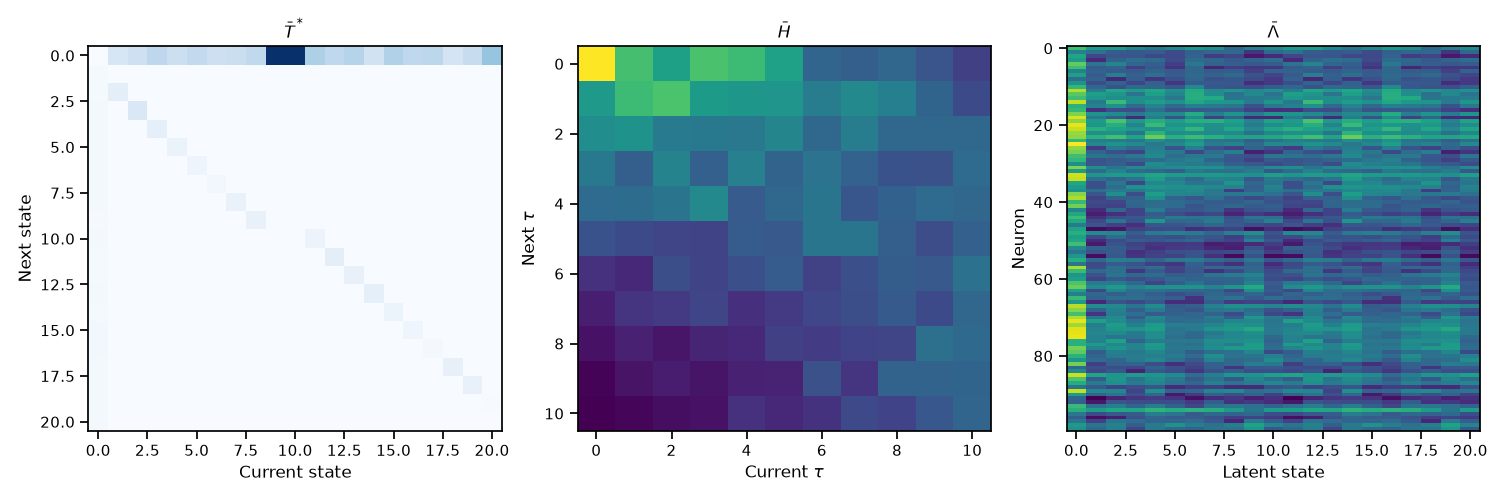

In [29]:
# get the best model params
best_iter = np.argmin(all_losses[:, -1])
best_model_params = model_params[best_iter]
log_T = best_model_params["log_T"]
log_H = best_model_params["log_H"]
log_Lambda = best_model_params["log_Lambda"]

# compute the mean of the log parameters across all iterations
mean_log_T = np.mean([model_params[iter]["log_T"] for iter in range(len(model_params))], axis=0)
mean_log_H = np.mean([model_params[iter]["log_H"] for iter in range(len(model_params))], axis=0)
mean_log_Lambda = np.mean([model_params[iter]["log_Lambda"] for iter in range(len(model_params))], axis=0)





# ============================================================
# PLOT FITTED MATRICES
# ============================================================

fig, axs = plt.subplots(1, 3, figsize=(15, 5))


# ------------------------------------------------------------
# T*
# ------------------------------------------------------------

axs[0].imshow(
    np.exp(log_T),
    aspect="auto",
    cmap='Blues'
)

axs[0].set_title(r"$T^*$")
axs[0].set_xlabel("Current state")
axs[0].set_ylabel("Next state")


# ------------------------------------------------------------
# H
# ------------------------------------------------------------

axs[1].imshow(
    np.exp(log_H),
    aspect="auto"
)

axs[1].set_title(r"$H$")
axs[1].set_xlabel(r"Current $\tau$")
axs[1].set_ylabel(r"Next $\tau$")


# ------------------------------------------------------------
# Lambda
#
# Lambda has shape:
#     (latent state, neuron)
#
# Find the latent state at which EACH NEURON has its
# maximum firing rate.
# ------------------------------------------------------------

Lambda = np.exp(log_Lambda)

peak_state = np.argmax(
    Lambda,
    axis=0
)

# Sort NEURONS according to their preferred latent state
neuron_order = np.argsort(peak_state)

# Keep latent states in their original order.
# Only reorder neurons.
Lambda_sorted = Lambda[:, neuron_order]


# Plot:
# rows    = neurons
# columns = latent states
axs[2].imshow(
    Lambda_sorted.T,
    aspect="auto"
)

axs[2].set_title(r"$\Lambda$")
axs[2].set_xlabel("Latent state")
axs[2].set_ylabel("Neuron")


plt.tight_layout()
plt.show()


# now plot the means

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# ------------------------------------------------------------
# mean T*
# ------------------------------------------------------------

axs[0].imshow(
    np.exp(mean_log_T),
    aspect="auto",
    cmap='Blues'
)

axs[0].set_title(r"$\bar{T}^*$")
axs[0].set_xlabel("Current state")
axs[0].set_ylabel("Next state")

# ------------------------------------------------------------
# mean H
# ------------------------------------------------------------

axs[1].imshow(
    np.exp(mean_log_H),
    aspect="auto"
)

axs[1].set_title(r"$\bar{H}$")
axs[1].set_xlabel(r"Current $\tau$")
axs[1].set_ylabel(r"Next $\tau$")

# ------------------------------------------------------------
# mean Lambda
# ------------------------------------------------------------

mean_Lambda = np.exp(mean_log_Lambda)

peak_state = np.argmax(
    mean_Lambda,
    axis=0
)

neuron_order = np.argsort(peak_state)
mean_Lambda_sorted = mean_Lambda[:, neuron_order]

axs[2].imshow(
    mean_Lambda_sorted.T,
    aspect="auto"
)

axs[2].set_title(r"$\bar{\Lambda}$")
axs[2].set_xlabel("Latent state")
axs[2].set_ylabel("Neuron")

plt.tight_layout()
plt.show()


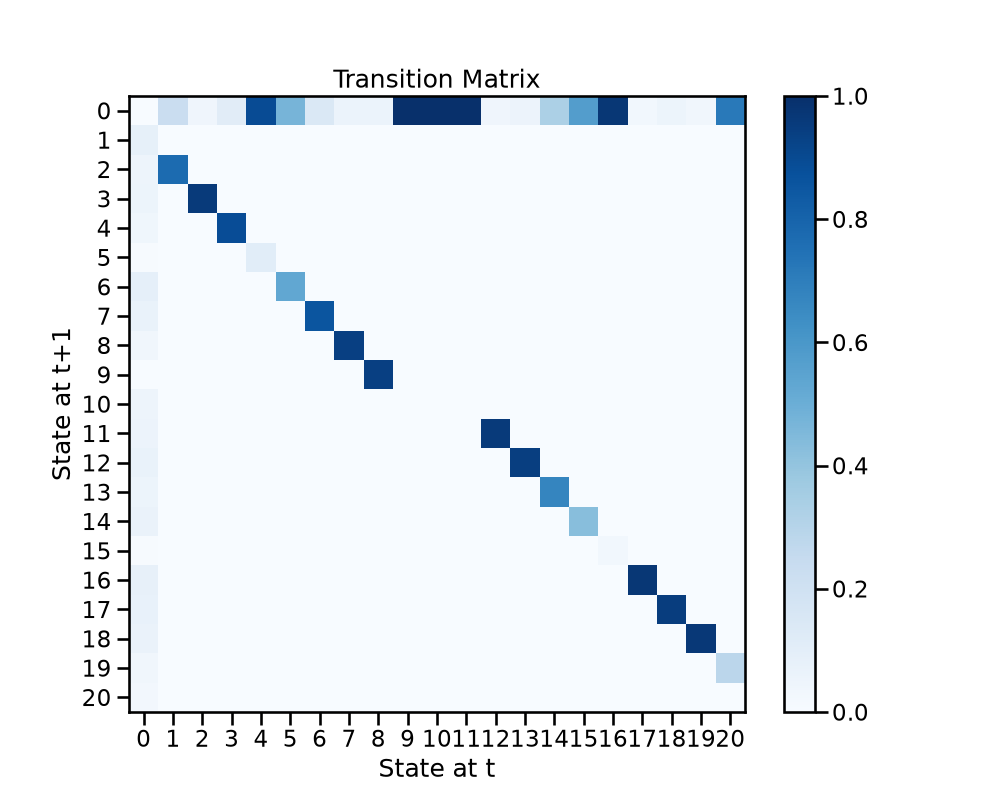

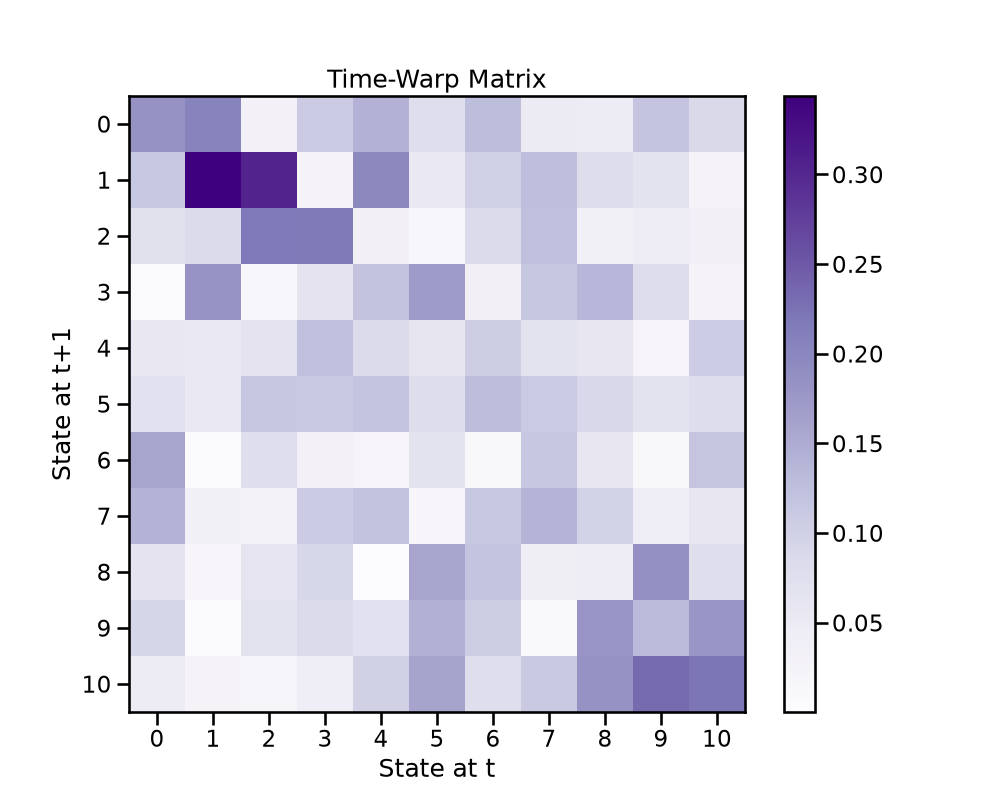

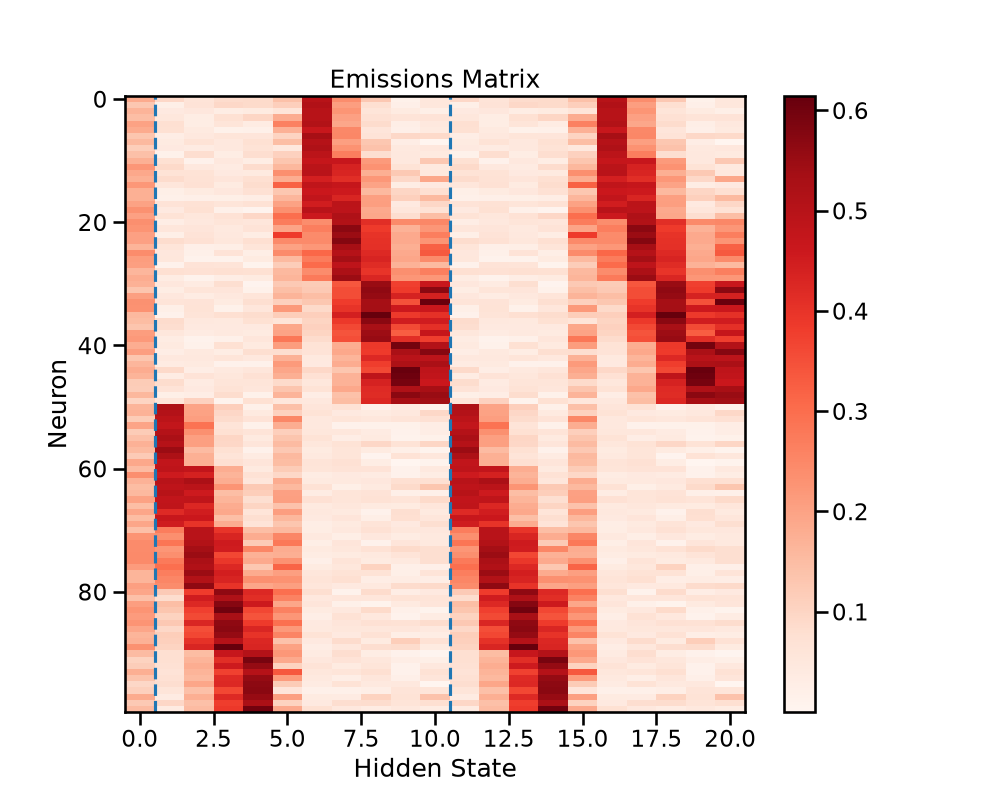

In [159]:
# =============================================================================
# VISUALIZE
# =============================================================================


# visualize transition matrix
plt.figure(figsize=(10, 8))
plt.title("Transition Matrix")
plt.imshow(np.exp(log_T), cmap="Blues")
plt.colorbar()
plt.xticks(np.arange(M))
plt.yticks(np.arange(M))
plt.xlabel("State at t")
plt.ylabel("State at t+1")
plt.show()


# visualize time-warp matrix
plt.figure(figsize=(10, 8))
plt.title("Time-Warp Matrix")
plt.imshow(np.exp(log_H), cmap="Purples")
plt.colorbar()
plt.xticks(np.arange(S))
plt.yticks(np.arange(S))
plt.xlabel("State at t")
plt.ylabel("State at t+1")
plt.show()



plt.figure(figsize=(10, 8))
plt.title("Emissions Matrix")
plt.imshow(
    np.exp(log_Lambda).T,
    cmap="Reds",
    aspect="auto"
)
plt.colorbar()
plt.xlabel("Hidden State")
plt.ylabel("Neuron")
plt.axvline(0.5, linestyle="--")               # hub boundary
plt.axvline(nForward + 0.5, linestyle="--")   # forward/reverse boundary
plt.show()

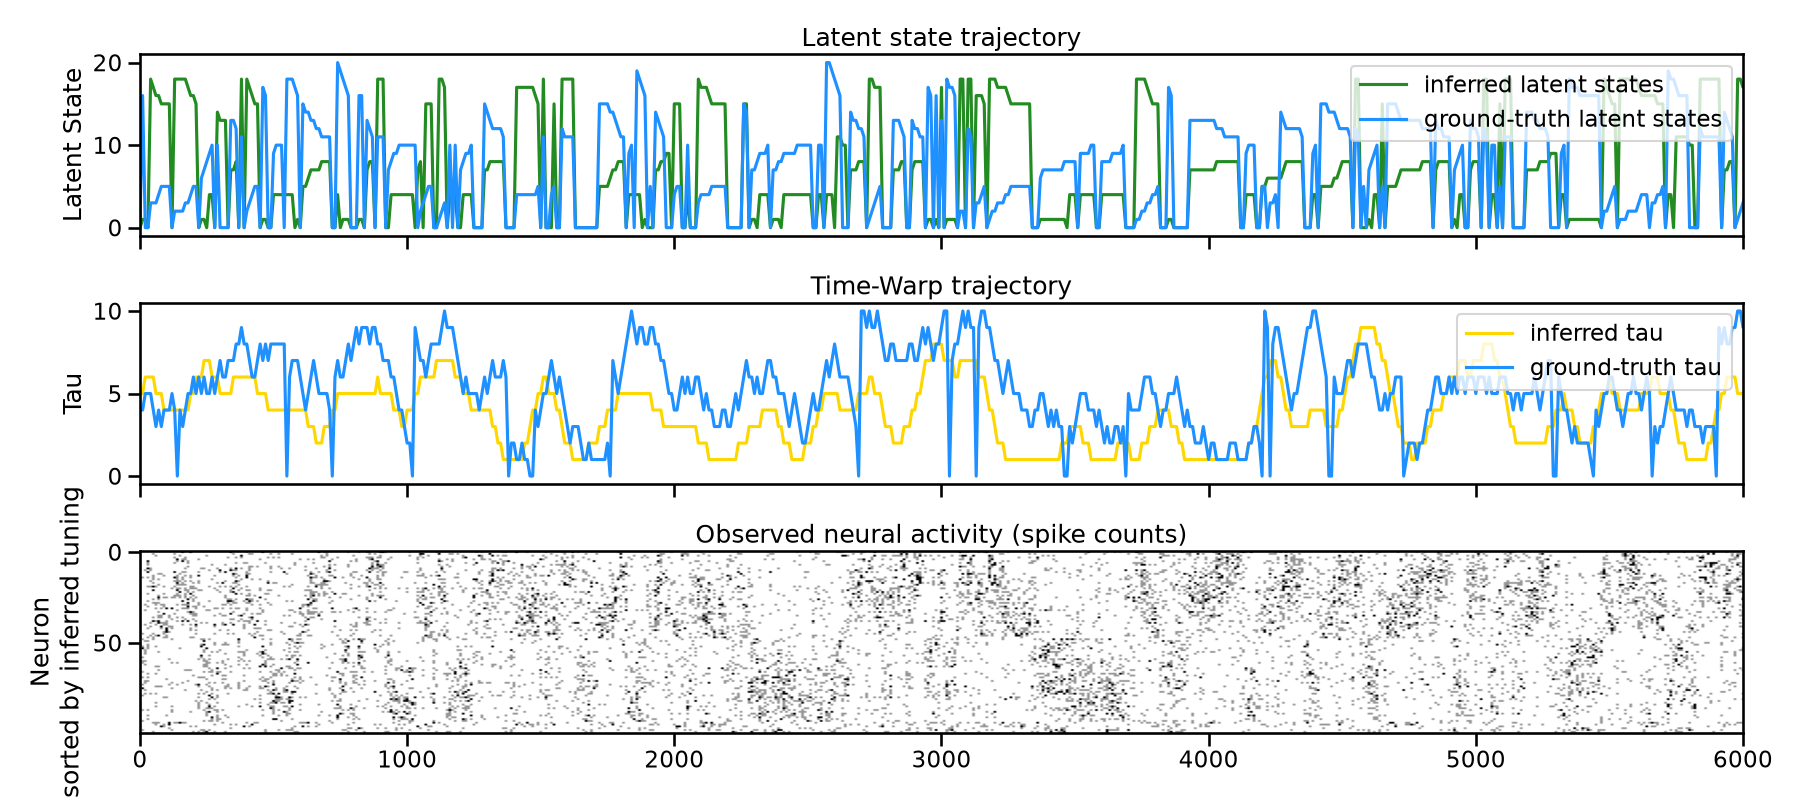

In [183]:
# plot the most likely sequence of hidden states and the real states

fig, axs = plt.subplots(3, 1, figsize=(18, 8), sharex=True)
axs[0].plot(state_sequence[0], label='inferred latent states', color = 'forestgreen')
axs[0].plot(Zs, label='ground-truth latent states', color = 'dodgerblue')
axs[0].set_title('Latent state trajectory')
axs[0].legend(loc = 'upper right')
axs[0].set_ylabel('Latent State')

axs[1].plot(best_tau_sequence_smoothed, label='inferred tau', color = 'gold')
axs[1].plot(taus, label='ground-truth tau', color = 'dodgerblue')
axs[1].set_title('Time-Warp trajectory')
axs[1].legend(loc='upper right')
axs[1].set_ylabel('Tau')

# plot the Y but sorted by the learned emissions matrix sorting
Y_sorted = Y[:, neuron_order]
axs[2].imshow(
    Y_sorted.T,
    aspect="auto",
    cmap="Greys",
    vmin = 0,
    vmax = 2
)
axs[2].set_title('Observed neural activity (spike counts)')
axs[2].set_ylabel('Neuron\nsorted by inferred tuning')
axs[0].set_xlim(6000, 6600)
axs[1].set_xlim(6000, 6600)
axs[2].set_xlim(6000, 6600)

# cahnge the x ticks so that they are all divided by 20
axs[2].set_xticks(np.arange(6000, 6601, 100))
axs[2].set_xticklabels(np.arange(0, 601, 100) * 10)
plt.tight_layout()
plt.show()


In [69]:
# compute correlation between real and inferred tau
tau_correlation = np.corrcoef(taus, state_sequence[1])[0, 1]
print(tau_correlation)

# 

0.28849591702435573


(10000, 100)


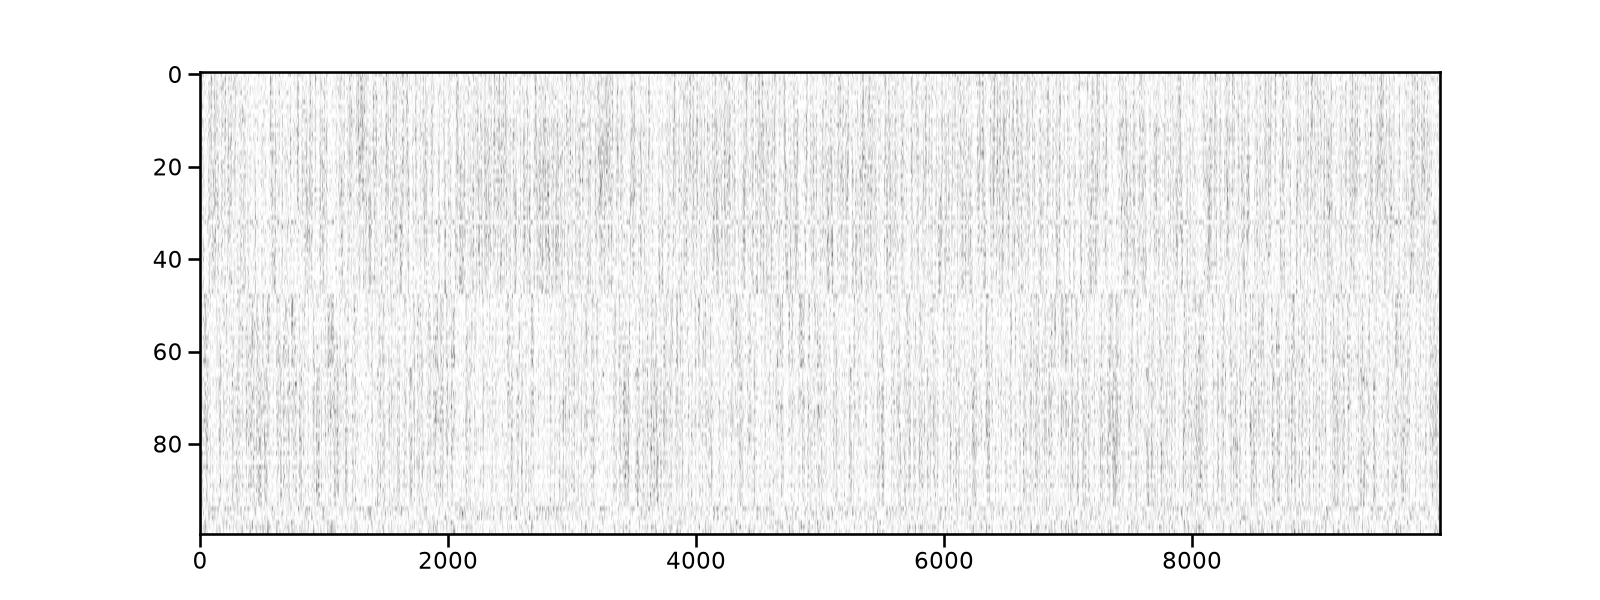

In [70]:
# plot the Y but sorted by the learned emissions matrix sorting
print(Y.shape)
Y_sorted = Y[:, neuron_order]

plt.figure(figsize=(16, 6))
plt.imshow(
    Y_sorted.T,
    aspect="auto",
    cmap="Greys",
    vmin = 0,
    vmax = 2
)
plt.show()